# NB3 · Choose a smoothing window

This notebook goes with **NB1, part A (speeds)**. In class we use its interactive explorer, `NB3_smoothing_explorer.html`, which opens in any web browser.

**Purpose:** Show how the Savitzky–Golay window changes the velocity that you calculate from a noisy track of a swimming bacterium. Use the result to select a window for your recordings.

**Required input:** None. The notebook makes a synthetic path of a run-and-tumble cell with a known velocity. No dataset is necessary.

**Result:** A figure that compares raw, best, and too-smooth velocity, and the interactive explorer.

A velocity calculated directly from frame-to-frame differences of a noisy track is mostly noise. A Savitzky–Golay filter smooths position and velocity together. The filter fits a polynomial to the frames in a window around each frame. The smoothed position is the value of this polynomial at the center frame. The velocity is the first derivative of the same polynomial.

A short window keeps fast motion, but noise goes through the filter. A long window removes noise, but it also changes the motion: it rounds turns and the start and end of movement bouts. This change is the bias. For a swimming bacterium the fastest motion is a tumble: the cell slows down and turns in about 0.15 s, only 4–5 frames at 30 frames per second. The noise error decreases when the window becomes longer, and the bias increases. The best window is near the point where the two errors are equal.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display
from scipy.integrate import cumulative_trapezoid
from scipy.signal import savgol_coeffs, savgol_filter

## 1. Set the frame rate and noise level

The window unit is frames, so the duration of a window depends on the frame rate. Use the camera rate of your recordings.

To measure the noise level of your setup, track cells that do not move (for example, cells stuck to the glass). The standard deviation of `x` and `y` in that period is the tracking noise.

In [2]:
FRAME_RATE_HZ = 30.0  # Camera rate of the recordings.
NOISE_SD_UM = 0.2  # Standard deviation of the localization noise on each axis (µm).
EXAMPLE_WINDOW = 7  # The window used in NB1, in frames.
ORDER = 2  # Polynomial order of the filter (NB1 uses 2).
TOO_SMOOTH_WINDOW = 31  # A window that is too long, for comparison.
PATH_ZOOM_S = (4.6, 5.9)  # Time range of the path panel. It contains one tumble.
DURATION_S = 12.0
RANDOM_SEED = 11

dt = 1.0 / FRAME_RATE_HZ

## 2. Make a synthetic swimming path

The cell runs at 25 µm/s, and its direction wobbles slowly. Six tumbles of 0.1 to 0.2 s interrupt the runs: during a tumble the cell slows to 5 µm/s and turns by 55° to 110°. The true velocity is known, so the notebook can measure the error of each estimate. The notebook adds independent random noise to `x` and `y`.

In [3]:
def logistic(t, width_s):
    return 1.0 / (1.0 + np.exp(-t / width_s))


RUN_SPEED = 25.0  # µm/s
TUMBLE_SPEED = 5.0  # µm/s
TUMBLES = [(1.6, 0.15, 75.0), (3.3, 0.12, -60.0), (5.1, 0.20, 110.0), (7.4, 0.15, -85.0), (9.1, 0.10, 55.0), (10.6, 0.18, -100.0)]
# Each tumble: start (s), duration (s), turn (degrees).


def simulate_swimmer(frame_rate_hz, duration_s, oversample=20):
    # Return a smooth run-and-tumble path, sampled at the frame rate, with its exact velocity.
    # The path is integrated on a grid 20 times finer than the frames, so that position and velocity agree.
    t = np.arange(round(duration_s * frame_rate_hz * oversample)) / (frame_rate_hz * oversample)
    speed = np.full_like(t, RUN_SPEED)
    heading_deg = 20.0 * np.sin(2 * np.pi * t / 5.0)  # slow wobble of the direction during runs
    for start_s, length_s, turn_deg in TUMBLES:
        speed -= (RUN_SPEED - TUMBLE_SPEED) * (logistic(t - start_s, 0.02) - logistic(t - start_s - length_s, 0.02))
        heading_deg += turn_deg * logistic(t - start_s - length_s / 2, length_s / 6)

    heading = np.deg2rad(heading_deg)
    vx = speed * np.cos(heading)
    vy = speed * np.sin(heading)
    x = cumulative_trapezoid(vx, t, initial=0.0)
    y = cumulative_trapezoid(vy, t, initial=0.0)
    frames = slice(None, None, oversample)
    return {"t": t[frames], "x": x[frames], "y": y[frames], "vx": vx[frames], "vy": vy[frames], "speed": speed[frames]}


cell = simulate_swimmer(FRAME_RATE_HZ, DURATION_S)
unit_noise = np.random.default_rng(RANDOM_SEED).standard_normal((2, cell["t"].size))
x_noisy = cell["x"] + NOISE_SD_UM * unit_noise[0]
y_noisy = cell["y"] + NOISE_SD_UM * unit_noise[1]

print(f"Frames: {cell['t'].size} at {FRAME_RATE_HZ:g} Hz")
print(f"True speed: {RUN_SPEED:g} µm/s during runs, {TUMBLE_SPEED:g} µm/s during tumbles")

Frames: 360 at 30 Hz
True speed: 25 µm/s during runs, 5 µm/s during tumbles


## 3. Measure velocity error for each window

The notebook uses `scipy.signal.savgol_filter` with its default edge mode. The error uses only interior frames, so the edge handling of long windows does not change the comparison.

- **Bias** is the error when the filter operates on the path without noise.
- **Noise error** is the expected effect of the noise: √2 × σ × the norm of the derivative coefficients.
- **Total error** is the square root of the sum of the two squared errors.

The raw estimate is the central difference, `np.gradient`. Its error (about 6 µm/s here) is the RMS error of the two-dimensional velocity vector, and the central difference averages over two frames. NB1 quotes a larger number, 8.5 µm/s, because it uses the difference of consecutive frames, $\sqrt2\,\sigma/\Delta t$, for one velocity component. Both describe the same noise.


In [4]:
WINDOWS = np.arange(5, 42, 2)
ORDERS = (2, 4, 6)
EDGE_FRAMES = int(WINDOWS.max()) // 2
interior = slice(EDGE_FRAMES, -EDGE_FRAMES)


def sg_velocity(x, y, window, order):
    return (
        savgol_filter(x, window, order, deriv=1, delta=dt),
        savgol_filter(y, window, order, deriv=1, delta=dt),
    )


def raw_velocity(x, y):
    return np.gradient(x, dt), np.gradient(y, dt)


def velocity_rms_error(vx_est, vy_est):
    squared = (vx_est - cell["vx"]) ** 2 + (vy_est - cell["vy"]) ** 2
    return float(np.sqrt(np.mean(squared[interior])))


def error_curve(order, noise_sd_um):
    # Rows: window, bias, noise error, total error (µm/s).
    rows = []
    for window in WINDOWS[WINDOWS > order]:
        bias = velocity_rms_error(*sg_velocity(cell["x"], cell["y"], window, order))
        coeffs = savgol_coeffs(window, order, deriv=1, delta=dt, use="dot")
        noise = float(np.sqrt(2.0) * noise_sd_um * np.linalg.norm(coeffs))
        rows.append((window, bias, noise, np.hypot(bias, noise)))
    return np.array(rows)


curve = error_curve(ORDER, NOISE_SD_UM)
best_window = int(curve[np.argmin(curve[:, 3]), 0])

estimates = {
    "Raw difference": raw_velocity(x_noisy, y_noisy),
    f"Best window ({best_window} frames)": sg_velocity(x_noisy, y_noisy, best_window, ORDER),
    f"NB1 window ({EXAMPLE_WINDOW} frames)": sg_velocity(x_noisy, y_noisy, EXAMPLE_WINDOW, ORDER),
    f"Too smooth ({TOO_SMOOTH_WINDOW} frames)": sg_velocity(x_noisy, y_noisy, TOO_SMOOTH_WINDOW, ORDER),
}
print(f"Polynomial order {ORDER}, noise {NOISE_SD_UM:g} µm, {FRAME_RATE_HZ:g} Hz")
for name, (vx_est, vy_est) in estimates.items():
    print(f"{name:32s} velocity RMS error {velocity_rms_error(vx_est, vy_est):5.2f} µm/s")
print(f"Best window: {best_window} frames = {best_window / FRAME_RATE_HZ:.2f} s")

Polynomial order 2, noise 0.2 µm, 30 Hz
Raw difference                   velocity RMS error  6.12 µm/s
Best window (9 frames)           velocity RMS error  1.79 µm/s
NB1 window (7 frames)            velocity RMS error  1.89 µm/s
Too smooth (31 frames)           velocity RMS error  4.66 µm/s
Best window: 9 frames = 0.30 s


## 4. Compare raw, best, and too-smooth velocity

The left panels show speed over time. The raw difference is mostly noise. The best window follows the true speed. The too-smooth window has little noise, but it is wrong: it fills in the tumbles, so the cell seems to slow down less and for longer.

The upper-right panel shows the error against the window length. The noise error decreases and the bias increases, so the total error has a minimum. The lower-right panel shows the path around one tumble. A long window also cuts the corner of the path.

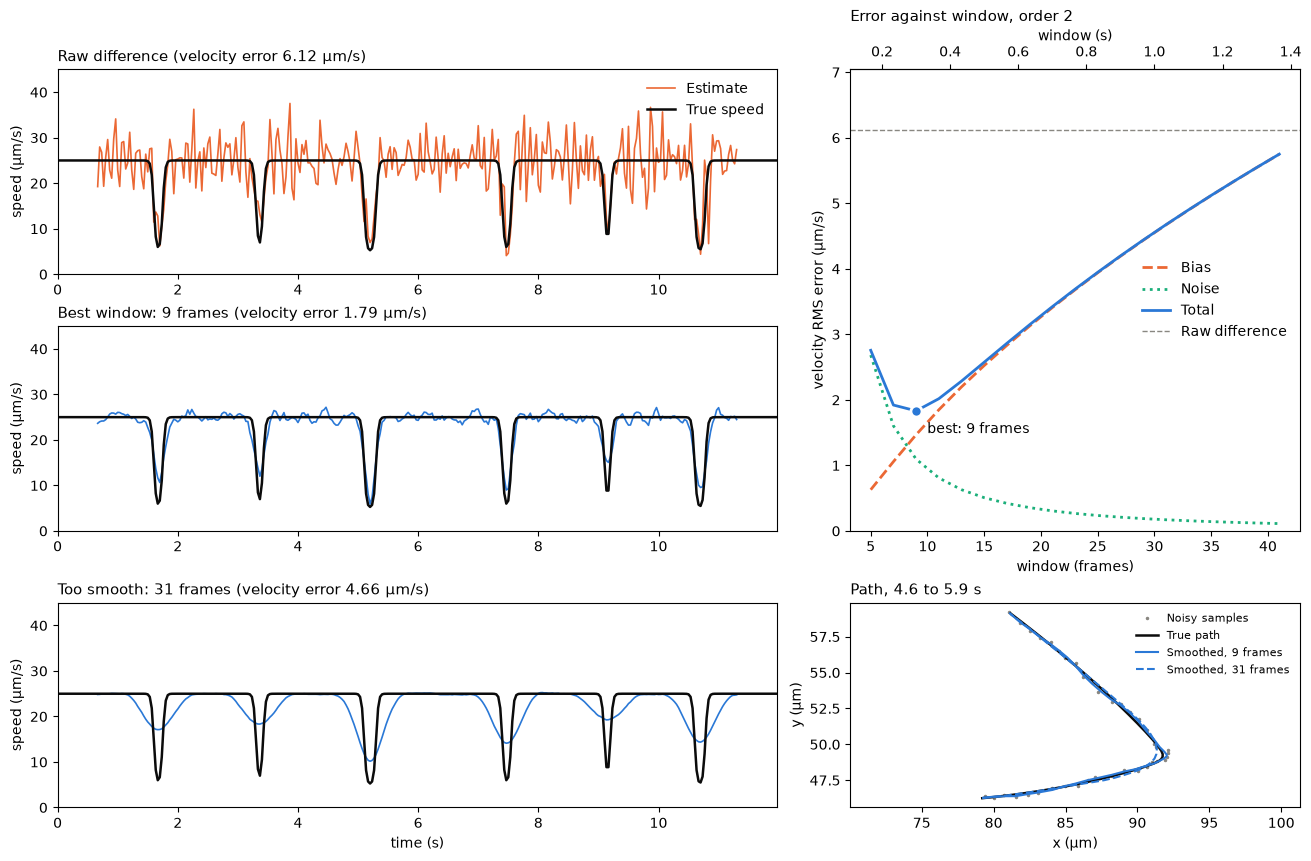

In [5]:
COLORS = {
    "true": "#0b0b0b",
    "raw": "#eb6834",
    "estimate": "#2a78d6",
    "noise": "#1baf7a",
    "muted": "#898781",
}

t = cell["t"]
fig, axes = plt.subplot_mosaic(
    [["raw", "error"], ["best", "error"], ["smooth", "path"]],
    figsize=(13, 8.5),
    width_ratios=[1.6, 1],
    layout="constrained",
)
panels = [
    ("raw", "Raw difference", raw_velocity(x_noisy, y_noisy)),
    ("best", f"Best window: {best_window} frames", sg_velocity(x_noisy, y_noisy, best_window, ORDER)),
    ("smooth", f"Too smooth: {TOO_SMOOTH_WINDOW} frames", sg_velocity(x_noisy, y_noisy, TOO_SMOOTH_WINDOW, ORDER)),
]
for key, title, (vx_est, vy_est) in panels:
    ax = axes[key]
    error = velocity_rms_error(vx_est, vy_est)
    color = COLORS["raw"] if key == "raw" else COLORS["estimate"]
    ax.plot(t[interior], np.hypot(vx_est, vy_est)[interior], color=color, lw=1.2, label="Estimate")
    ax.plot(t, cell["speed"], color=COLORS["true"], lw=1.8, label="True speed")
    ax.set_title(f"{title} (velocity error {error:.2f} µm/s)", loc="left", fontsize=11)
    ax.set_ylabel("speed (µm/s)")
    ax.set_ylim(0, 45)
    ax.set_xlim(t[0], t[-1])
axes["raw"].legend(loc="upper right", frameon=False)
axes["smooth"].set_xlabel("time (s)")

ax = axes["error"]
ax.plot(curve[:, 0], curve[:, 1], color=COLORS["raw"], ls="--", lw=2, label="Bias")
ax.plot(curve[:, 0], curve[:, 2], color=COLORS["noise"], ls=":", lw=2, label="Noise")
ax.plot(curve[:, 0], curve[:, 3], color=COLORS["estimate"], lw=2, label="Total")
raw_error = velocity_rms_error(*raw_velocity(x_noisy, y_noisy))
ax.axhline(raw_error, color=COLORS["muted"], ls="--", lw=1, label="Raw difference")
best_total = curve[curve[:, 0] == best_window, 3][0]
ax.plot(best_window, best_total, "o", color=COLORS["estimate"], ms=8, mec="white", mew=2)
ax.annotate(f"best: {best_window} frames", (best_window, best_total), (8, -16), textcoords="offset points")
ax.set_xlabel("window (frames)")
ax.set_ylabel("velocity RMS error (µm/s)")
ax.set_title(f"Error against window, order {ORDER}", loc="left", fontsize=11)
ax.set_ylim(0, raw_error * 1.15)
ax.legend(frameon=False)
seconds_axis = ax.secondary_xaxis("top", functions=(lambda w: w / FRAME_RATE_HZ, lambda s: s * FRAME_RATE_HZ))
seconds_axis.set_xlabel("window (s)")

ax = axes["path"]
zoom = slice(int(PATH_ZOOM_S[0] * FRAME_RATE_HZ), int(PATH_ZOOM_S[1] * FRAME_RATE_HZ))
ax.plot(x_noisy[zoom], y_noisy[zoom], ".", color=COLORS["muted"], ms=3, label="Noisy samples")
ax.plot(cell["x"][zoom], cell["y"][zoom], color=COLORS["true"], lw=1.8, label="True path")
for window, style in [(best_window, "-"), (TOO_SMOOTH_WINDOW, "--")]:
    xs = savgol_filter(x_noisy, window, ORDER)
    ys = savgol_filter(y_noisy, window, ORDER)
    ax.plot(xs[zoom], ys[zoom], color=COLORS["estimate"], ls=style, lw=1.5, label=f"Smoothed, {window} frames")
ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("x (µm)")
ax.set_ylabel("y (µm)")
ax.set_title(f"Path, {PATH_ZOOM_S[0]:g} to {PATH_ZOOM_S[1]:g} s", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8)
plt.show()

## 5. Explore the window interactively

In class, open `NB3_smoothing_explorer.html` in a web browser; it needs no Python. You can also run the next cell in JupyterLab or VS Code. Move the window slider, change the polynomial order and the noise level, or use the buttons. Move the pointer over a chart to read its values. The explorer uses the `savgol_coeffs` coefficients and the path from the previous sections, so its values agree with section 3.

The explorer draws its charts with its own code, so it needs no internet connection and no extra package. Jupyter runs the scripts in a saved output only if you trust the notebook, so run the cell if the explorer does not respond. The cell also saves the explorer as `NB3_smoothing_explorer.html` next to the notebook. Open this file in a web browser to use the explorer without Python. GitHub does not run the explorer; use the figure in section 4 instead.

In [6]:
EXPLORER_TEMPLATE = r'''<div id="__UID__">
<style>
#__UID__{background:#ffffff;color:#0b0b0b;font-family:system-ui,-apple-system,'Segoe UI',sans-serif;padding:16px;border:1px solid #e1e0d9;border-radius:12px;max-width:820px;box-sizing:border-box}
#__UID__ .row{display:flex;align-items:center;gap:12px;margin:0 0 10px;flex-wrap:wrap}
#__UID__ .lab{font-size:13px;color:#52514e;min-width:110px}
#__UID__ .val{font-size:13px;font-weight:500;min-width:130px;font-variant-numeric:tabular-nums}
#__UID__ button,#__UID__ select{font:inherit;font-size:13px;padding:5px 12px;border:1px solid #c3c2b7;border-radius:8px;background:#ffffff;color:#0b0b0b;cursor:pointer}
#__UID__ button:hover{background:#f5f4f0}
#__UID__ .cards{display:grid;grid-template-columns:repeat(auto-fit,minmax(170px,1fr));gap:12px;margin:14px 0 6px}
#__UID__ .card{background:#f5f4f0;border-radius:8px;padding:10px 14px}
#__UID__ .card p{margin:0}
#__UID__ .cl{font-size:12px;color:#52514e}
#__UID__ .cv{font-size:20px;font-weight:500;font-variant-numeric:tabular-nums}
#__UID__ .leg{display:flex;flex-wrap:wrap;gap:14px;font-size:12px;color:#52514e;margin:14px 0 4px}
#__UID__ .leg span{display:flex;align-items:center;gap:5px}
#__UID__ .sw{display:inline-block;width:16px;height:0;border-top-width:2px;border-top-style:solid}
#__UID__ .cap{font-size:13px;color:#52514e;margin:16px 0 2px;font-weight:500}
#__UID__ svg{display:block;width:100%;height:auto}
#__UID__ svg text{font-family:inherit}
#__UID__ .rd{font-size:12px;color:#52514e;min-height:16px;margin:2px 0 0;font-variant-numeric:tabular-nums}
</style>
<p data-out="msg" style="font-size:13px;color:#a32d2d;margin:0 0 10px">The explorer is not running. Run this cell. Jupyter runs the scripts in the saved output of a notebook only if you trust the notebook. You can also open NB3_smoothing_explorer.html in a web browser.</p>
<div class="row">
<button data-act="raw">Raw difference</button><button data-act="best">Best window</button><button data-act="pipe">NB1 window</button><button data-act="smooth">Too smooth</button>
</div>
<div class="row"><span class="lab">Window (frames)</span><input type="range" data-in="w" min="5" max="81" step="2" style="flex:1;min-width:160px"><span class="val" data-out="w"></span></div>
<div class="row"><span class="lab">Polynomial order</span><select data-in="p"><option value="2">2</option><option value="4">4</option><option value="6">6</option></select>
<span class="lab" style="margin-left:12px;min-width:0">Noise &sigma; (&micro;m)</span><input type="range" data-in="s" min="0.05" max="0.5" step="0.05" style="flex:1;min-width:120px"><span class="val" data-out="s" style="min-width:40px"></span></div>
<div class="cards">
<div class="card"><p class="cl">Raw velocity error</p><p class="cv" data-out="raw">&ndash;</p></div>
<div class="card"><p class="cl">Current velocity error</p><p class="cv" data-out="cur">&ndash;</p></div>
<div class="card"><p class="cl">Best window for these settings</p><p class="cv" data-out="best">&ndash;</p></div>
</div>
<p class="cap">Speed over time</p>
<div class="leg"><span><i class="sw" style="border-color:#0b0b0b"></i>True speed</span><span><i class="sw" style="border-color:#eb6834;border-top-style:dotted"></i>Raw difference</span><span><i class="sw" style="border-color:#2a78d6"></i>Current estimate</span></div>
<svg data-chart="spd" viewBox="0 0 780 230" role="img" aria-label="True, raw and filtered speed over time"></svg>
<p class="rd" data-out="rd-spd"></p>
<p class="cap">Velocity error against window length</p>
<div class="leg"><span><i class="sw" style="border-color:#eb6834;border-top-style:dashed"></i>Bias</span><span><i class="sw" style="border-color:#1baf7a;border-top-style:dotted"></i>Noise</span><span><i class="sw" style="border-color:#2a78d6"></i>Total RMS error</span><span><i class="sw" style="border-color:#898781;border-top-style:dashed"></i>Raw difference</span></div>
<svg data-chart="err" viewBox="0 0 780 230" role="img" aria-label="Bias, noise and total velocity error against window length"></svg>
<p class="rd" data-out="rd-err"></p>
<p class="cap">Path around one quick turn</p>
<div class="leg"><span><i class="sw" style="border-color:#0b0b0b"></i>True path</span><span><i class="sw" style="border-color:#898781;border-top-style:dotted"></i>Noisy samples</span><span><i class="sw" style="border-color:#2a78d6"></i>Smoothed path</span></div>
<svg data-chart="path" viewBox="0 0 780 300" role="img" aria-label="True path, noisy samples and smoothed path"></svg>
</div>
<script>
(function(){
const D=__DATA__;
const root=document.getElementById("__UID__");
const q=s=>root.querySelector(s);
q('[data-out="msg"]').style.display="none";
const C={ink:"#0b0b0b",blue:"#2a78d6",org:"#eb6834",aq:"#1baf7a",mut:"#898781",grid:"#e1e0d9"};
const NS="http://www.w3.org/2000/svg";
function el(tag,a,p){const e=document.createElementNS(NS,tag);for(const k in a)e.setAttribute(k,a[k]);if(p)p.appendChild(e);return e;}
function ticks(lo,hi,n){const raw=(hi-lo)/n,mag=Math.pow(10,Math.floor(Math.log10(raw))),f=raw/mag,st=(f<1.5?1:f<3?2:f<7?5:10)*mag,out=[];
 for(let k=Math.ceil(lo/st-1e-9);k*st<=hi+1e-9*st;k++)out.push(k*st);return out;}
const fmt=v=>String(+v.toPrecision(6));
// Draw one chart into an SVG element. The SVG has no external dependency.
function chart(svg,o){
 const vb=svg.viewBox.baseVal,w=vb.width,h=vb.height,m={l:54,r:14,t:10,b:38},pw=w-m.l-m.r,ph=h-m.t-m.b;
 let [x0,x1]=o.x,[y0,y1]=o.y;
 if(o.equal){const s=Math.max((x1-x0)/pw,(y1-y0)/ph),cx=(x0+x1)/2,cy=(y0+y1)/2;x0=cx-s*pw/2;x1=cx+s*pw/2;y0=cy-s*ph/2;y1=cy+s*ph/2;}
 const X=v=>m.l+(v-x0)/(x1-x0)*pw,Y=v=>m.t+(1-(v-y0)/(y1-y0))*ph;
 svg.textContent="";
 const id=root.id+"-clip-"+svg.dataset.chart;
 el("rect",{x:m.l,y:m.t,width:pw,height:ph},el("clipPath",{id},el("defs",{},svg)));
 const g=el("g",{},svg);
 for(const v of ticks(y0,y1,5)){el("line",{x1:m.l,x2:m.l+pw,y1:Y(v),y2:Y(v),stroke:C.grid},g);el("text",{x:m.l-6,y:Y(v)+4,"text-anchor":"end","font-size":11,fill:C.mut},g).textContent=fmt(v);}
 for(const v of ticks(x0,x1,o.nx||8)){el("line",{x1:X(v),x2:X(v),y1:m.t,y2:m.t+ph,stroke:C.grid},g);el("text",{x:X(v),y:m.t+ph+15,"text-anchor":"middle","font-size":11,fill:C.mut},g).textContent=fmt(v);}
 el("text",{x:m.l+pw/2,y:h-4,"text-anchor":"middle","font-size":11,fill:C.mut},g).textContent=o.xl;
 el("text",{x:12,y:m.t+ph/2,"text-anchor":"middle","font-size":11,fill:C.mut,transform:"rotate(-90 12 "+(m.t+ph/2)+")"},g).textContent=o.yl;
 const pg=el("g",{"clip-path":"url(#"+id+")"},svg);
 for(const s of o.series){
  if(s.dot){for(const p of s.pts)if(p)el("circle",{cx:X(p[0]),cy:Y(p[1]),r:s.r||1.6,fill:s.color,stroke:s.ring||"none","stroke-width":s.ring?2:0},pg);continue;}
  let d="",pen=false;
  for(const p of s.pts){if(!p){pen=false;continue;}d+=(pen?"L":"M")+X(p[0]).toFixed(1)+" "+Y(p[1]).toFixed(1);pen=true;}
  el("path",{d,fill:"none",stroke:s.color,"stroke-width":s.width||2,"stroke-dasharray":s.dash||"none","stroke-linejoin":"round","stroke-linecap":"round"},pg);
 }
 if(!o.hover)return;
 const out=o.hover.out,cross=el("line",{y1:m.t,y2:m.t+ph,stroke:C.mut,visibility:"hidden"},svg);
 const hit=el("rect",{x:m.l,y:m.t,width:pw,height:ph,fill:"transparent"},svg);
 out.textContent=o.hover.idle;
 hit.addEventListener("mousemove",ev=>{const r=svg.getBoundingClientRect(),xs=(ev.clientX-r.left)*w/r.width,res=o.hover.fn(x0+(xs-m.l)/pw*(x1-x0));
  cross.setAttribute("x1",X(res.x));cross.setAttribute("x2",X(res.x));cross.setAttribute("visibility","visible");out.textContent=res.text;});
 hit.addEventListener("mouseleave",()=>{cross.setAttribute("visibility","hidden");out.textContent=o.hover.idle;});
}
const n=D.t.length,H=D.edge,fps=D.frameRate,dt=1/fps;
const filt=(a,c)=>{const h=(c.length-1)/2,o=new Array(n).fill(null);for(let t=H;t<n-H;t++){let s=0;for(let i=0;i<c.length;i++)s+=c[i]*a[t-h+i];o[t]=s;}return o;};
const rms=a=>{let s=0,k=0;for(const v of a){if(v!==null){s+=v;k++;}}return Math.sqrt(s/k);};
const verr=(fx,fy)=>rms(fx.map((v,i)=>v===null?null:(v-D.vx[i])**2+(fy[i]-D.vy[i])**2));
const CD=[-1/(2*dt),0,1/(2*dt)];
const st={w:D.defaults.window,p:D.defaults.order,s:D.defaults.noise,raw:false,best:D.defaults.window};
const W=q('[data-in="w"]'),P=q('[data-in="p"]'),S=q('[data-in="s"]');
W.min=D.wmin;W.max=D.wmax;
W.value=st.w;P.value=String(st.p);S.value=st.s;
const [P0,P1]=D.pathFrames;
const IDLE="Move the pointer over the chart to read the values.";
function curve(){return D.curves[st.p].map(([w,b,cn])=>{const nz=Math.SQRT2*st.s*cn;return{w,b,nz,tot:Math.hypot(b,nz)};});}
function render(){
 const nx=D.x.map((v,i)=>v+st.s*D.ex[i]),ny=D.y.map((v,i)=>v+st.s*D.ey[i]);
 const cv=curve(),best=cv.reduce((a,b)=>b.tot<a.tot?b:a);st.best=best.w;
 const rx=filt(nx,CD),ry=filt(ny,CD),rawE=verr(rx,ry);
 let fx=rx,fy=ry,px=null,py=null;
 if(!st.raw){const c=D.coeffs[st.p][st.w];fx=filt(nx,c[1]);fy=filt(ny,c[1]);px=filt(nx,c[0]);py=filt(ny,c[0]);}
 const curE=verr(fx,fy);
 q('[data-out="w"]').textContent=st.raw?"raw difference":st.w+" ("+(st.w/fps).toFixed(2)+" s)";
 q('[data-out="s"]').textContent=st.s.toFixed(2);
 q('[data-out="raw"]').textContent=rawE.toFixed(2)+" µm/s";
 q('[data-out="cur"]').textContent=curE.toFixed(2)+" µm/s";
 q('[data-out="best"]').textContent=best.w+" frames · "+(best.w/fps).toFixed(2)+" s";
 const rs=rx.map((v,i)=>v===null?null:Math.hypot(v,ry[i])),es=fx.map((v,i)=>v===null?null:Math.hypot(v,fy[i]));
 const pts=a=>a.map((v,i)=>v===null?null:[D.t[i],v]);
 const spdSeries=[{pts:pts(rs),color:C.org,width:1,dash:"2 2"},{pts:pts(D.speed),color:C.ink,width:2}];
 if(!st.raw)spdSeries.push({pts:pts(es),color:C.blue,width:2});
 const top=Math.ceil(Math.max(30,...rs.filter(v=>v!==null))/5)*5;
 chart(q('[data-chart="spd"]'),{x:[D.t[0],D.t[n-1]],y:[0,top],nx:10,xl:"time (s)",yl:"speed (µm/s)",series:spdSeries,
  hover:{out:q('[data-out="rd-spd"]'),idle:IDLE,fn:xv=>{const i=Math.min(n-1,Math.max(0,Math.round(xv*fps)));
   const f=v=>v===null?"-":v.toFixed(1);
   return{x:D.t[i],text:"t = "+D.t[i].toFixed(2)+" s · true "+f(D.speed[i])+" · raw "+f(rs[i])+(st.raw?"":" · current "+f(es[i]))+" µm/s"};}}});
 const cur=cv.find(o=>o.w===st.w);
 const errSeries=[
  {pts:[[D.wmin,rawE],[D.wmax,rawE]],color:C.mut,width:1,dash:"6 4"},
  {pts:cv.map(o=>[o.w,o.b]),color:C.org,dash:"6 4"},
  {pts:cv.map(o=>[o.w,o.nz]),color:C.aq,dash:"2 3"},
  {pts:cv.map(o=>[o.w,o.tot]),color:C.blue}];
 if(!st.raw&&cur)errSeries.push({dot:true,pts:[[st.w,cur.tot]],color:C.blue,r:6,ring:"#ffffff"});
 chart(q('[data-chart="err"]'),{x:[D.wmin,D.wmax],y:[0,Math.ceil(Math.max(rawE,cv[cv.length-1].tot)*1.1)],xl:"window (frames)",yl:"velocity RMS error (µm/s)",series:errSeries,
  hover:{out:q('[data-out="rd-err"]'),idle:IDLE,fn:xv=>{const o=cv.reduce((a,b)=>Math.abs(b.w-xv)<Math.abs(a.w-xv)?b:a);
   return{x:o.w,text:"window "+o.w+" frames ("+(o.w/fps).toFixed(2)+" s) · bias "+o.b.toFixed(2)+" · noise "+o.nz.toFixed(2)+" · total "+o.tot.toFixed(2)+" µm/s"};}}});
 const seg=(a,b)=>a.slice(P0,P1).map((v,i)=>[v,b[i+P0]]);
 const truePath=seg(D.x,D.y),noisyPath=seg(nx,ny),all=truePath.concat(noisyPath);
 const xs=all.map(p=>p[0]),ys=all.map(p=>p[1]),pad=0.3;
 const pathSeries=[{dot:true,pts:noisyPath,color:C.mut,r:1.8},{pts:truePath,color:C.ink,width:2}];
 if(!st.raw)pathSeries.push({pts:seg(px,py),color:C.blue,width:2});
 chart(q('[data-chart="path"]'),{x:[Math.min(...xs)-pad,Math.max(...xs)+pad],y:[Math.min(...ys)-pad,Math.max(...ys)+pad],equal:true,xl:"x (µm)",yl:"y (µm)",series:pathSeries});
}
function setW(w){st.w=Math.min(D.wmax,Math.max(w,D.wmin,st.p+1));W.value=st.w;}
W.oninput=()=>{st.raw=false;setW(+W.value);render();};
P.onchange=()=>{st.p=+P.value;st.raw=false;setW(st.w);render();};
S.oninput=()=>{st.s=+S.value;render();};
root.querySelectorAll("button").forEach(b=>b.onclick=()=>{const a=b.dataset.act;
 if(a==="raw"){st.raw=true;}
 else if(a==="best"){st.raw=false;render();setW(st.best);}
 else if(a==="pipe"){st.raw=false;setW(D.defaults.window);}
 else{st.raw=false;setW(D.defaults.tooSmooth);}
 render();});
render();
})();
</script>'''

In [7]:
def rounded(values, digits=6):
    return [round(float(v), digits) for v in values]


def coefficient_list(window, order, deriv):
    coeffs = savgol_coeffs(window, order, deriv=deriv, delta=dt, use="dot")
    return [float(f"{c:.8g}") for c in coeffs]


explorer_data = {
    "frameRate": FRAME_RATE_HZ,
    "wmin": int(WINDOWS.min()),
    "wmax": int(WINDOWS.max()),
    "edge": EDGE_FRAMES,
    "pathFrames": [int(PATH_ZOOM_S[0] * FRAME_RATE_HZ), int(PATH_ZOOM_S[1] * FRAME_RATE_HZ)],
    "defaults": {
        "window": EXAMPLE_WINDOW,
        "order": ORDER,
        "noise": NOISE_SD_UM,
        "tooSmooth": TOO_SMOOTH_WINDOW,
    },
    "t": rounded(cell["t"], 4),
    "x": rounded(cell["x"]),
    "y": rounded(cell["y"]),
    "vx": rounded(cell["vx"]),
    "vy": rounded(cell["vy"]),
    "speed": rounded(cell["speed"]),
    "ex": rounded(unit_noise[0]),
    "ey": rounded(unit_noise[1]),
    "coeffs": {},
    "curves": {},
}
for order in ORDERS:
    order_curve = error_curve(order, 1.0)
    # With a noise level of 1 µm, column 2 is sqrt(2) times the coefficient norm.
    explorer_data["curves"][order] = [
        [int(w), round(float(b), 6), round(float(nz) / np.sqrt(2.0), 8)] for w, b, nz, _ in order_curve
    ]
    explorer_data["coeffs"][order] = {
        int(w): [coefficient_list(int(w), order, 0), coefficient_list(int(w), order, 1)]
        for w in WINDOWS[WINDOWS > order]
    }

explorer_html = (
    EXPLORER_TEMPLATE.replace("__UID__", "sg-explorer")   # a fixed id, so the saved file is the same after every run
    .replace("__DATA__", json.dumps(explorer_data, separators=(",", ":")))
)
EXPLORER_FILE = "NB3_smoothing_explorer.html"
with open(EXPLORER_FILE, "w", encoding="utf-8") as f:
    f.write(
        '<!doctype html>\n<html lang="en"><head><meta charset="utf-8">'
        '<meta name="viewport" content="width=device-width, initial-scale=1">'
        "<title>Smoothing window explorer</title></head>\n"
        '<body style="margin:16px;background:#ffffff">\n' + explorer_html + "\n</body></html>\n"
    )
print(f"Saved the explorer as {EXPLORER_FILE}. Open it in a web browser to use it without Python.")
display(HTML(explorer_html))

Saved the explorer as NB3_smoothing_explorer.html. Open it in a web browser to use it without Python.


## 6. Apply the result to your recordings

The best window in this notebook depends on the noise and the motion of the synthetic cell. Do not copy the number. Use the same method with values from your recordings:

1. Measure the localization noise σ from cells that do not move.
2. Find the shortest real event that the analysis must keep. For *E. coli* this is a tumble (about 0.15 s).
3. Set `FRAME_RATE_HZ` and `NOISE_SD_UM` in section 1, and change the runs and tumbles in section 2 to match your cells. Run the notebook again.
4. Select a duration in seconds, then convert it to an odd number of frames for each frame rate.
5. On real data, examine the residual: the raw position minus the smoothed position. It must look like random noise. If tumbles show in the residual, the window is too long.

Angular velocity is more sensitive than speed, because tumbles are the fastest turns. A shorter window for angular velocity than for speed can be correct.